# Le contexte rétrécit la borne — entropie conditionnelle et taux de compression

**Série Compression — carnet 09b**

**Navigation** : [Index de la série](README.md) | [Compression-08 — Assemblage vectoriel d'un document](Compression-08-Assemblage-Vectoriel-Python.ipynb)

Le carnet 01 a établi la borne de Shannon : un code préfixe ne descend jamais sous l'entropie H(X) des symboles, symbole par symbole. Le carnet 04 a pourtant exhibé des codes (ANS) qui descendent sous l'entropie des octets d'un texte. Pas de contradiction : l'entropie d'octet calcule H(X) sur une source **sans mémoire** — chaque octet vu isolément. Or une vraie source a de la mémoire : la lettre qui suit un « q » n'est pas distribuée comme la lettre qui suit un espace. Le README de la série le formule : *« un codec peut descendre sous l'entropie des octets calculée sans tenir compte de leur contexte »*.

Ce carnet donne le corps de cette phrase : **l'entropie conditionnelle** H(X|Y), **l'information mutuelle** I(X;Y), et surtout le **taux d'entropie** d'un processus — la borne de compression *réelle* d'une source à mémoire. La démarche est la même que dans 01 : on construit la mesure à la main, on la vérifie sur une source dont la valeur **analytique** est connue, puis on la lit sur des sources où elle n'est pas connue — avec un témoin négatif qui garantit que la méthode ne fabrique pas de structure là où il n'y en a pas.

**Prérequis** : le carnet 01 (entropie, code préfixe) et des probabilités discrètes. Tout se calcule avec numpy, sur un alphabet de 27 symboles (a–z et l'espace), petit à dessein : les tables de contextes doivent être bien remplies pour que les estimations restent honnêtes.

## 1. Rappel — l'entropie comme borne

Pour une source **sans mémoire** — chaque symbole tiré indépendamment selon une loi `p` — l'entropie

    H(X) = − Σ_x p(x) log2 p(x)

se mesure en bits par symbole. Le théorème de codage des sources (carnet 01) dit qu'aucun code préfixe ne descend, en moyenne, sous `H(X)` : c'est la borne que Huffman sature.

Cette borne est **trop pessimiste** dès que la source a de la mémoire. Le symbole présent y dépend du passé, et un code qui *exploite* ce passé descend sous `H(X)`. L'écart entre `H(X)` et ce que le codage à contexte atteint réellement est précisément ce que ce carnet va mesurer.

In [1]:
# Fonctions d'information — alphabet de taille A (27 symboles : a-z + espace)
import numpy as np

A = 27

def entropie_de(counts):
    """Entropie de Shannon (bits) d'une loi donnée par ses effectifs."""
    counts = counts[counts > 0]
    p = counts / counts.sum()
    return float(-np.sum(p * np.log2(p)))

def h0(s):
    """Entropie par symbole H(X) — contexte de longueur 0 (source sans mémoire)."""
    return entropie_de(np.bincount(s, minlength=A))

def h_conditionnelle(s, order):
    """Entropie conditionnelle H(X_t | X_{t-1} ... X_{t-order}) en bits/symbole.

    On compte les paires (contexte de `order` symboles, symbole suivant) et on fait
    la moyenne, pondérée par P(contexte), de l'entropie du symbole suivant.
    """
    if len(s) <= order:
        return float('nan')
    ctx_len = len(s) - order
    ctx = np.zeros(ctx_len, dtype=np.int64)
    for k in range(order):
        ctx = ctx * A + s[k:ctx_len + k]
    cible = s[order:]
    nctx = A ** order
    jointe = np.bincount(ctx * A + cible, minlength=nctx * A).reshape(nctx, A)
    totale = float(jointe.sum())
    p_jointe = jointe / totale
    p_ctx = jointe.sum(axis=1)
    with np.errstate(divide='ignore', invalid='ignore'):
        p_cible = np.where(p_ctx[:, None] > 0,
                           jointe / np.where(p_ctx > 0, p_ctx, 1)[:, None], 0.0)
    masques = jointe > 0
    return float(-np.sum(p_jointe[masques] * np.log2(p_cible[masques])))

def info_mutuelle_ordre1(s):
    """I(X_t ; X_{t-1}) = H(X_t) - H(X_t | X_{t-1}), en bits/symbole."""
    prev, cur = s[:-1], s[1:]
    jointe = np.bincount(prev * A + cur, minlength=A * A).reshape(A, A)
    totale = float(jointe.sum())
    pj = jointe / totale
    pp = jointe.sum(axis=1) / totale
    pc = jointe.sum(axis=0) / totale
    masques = jointe > 0
    denom = np.broadcast_to(pp[:, None], (A, A)) * np.broadcast_to(pc[None, :], (A, A))
    return float(np.sum(pj[masques] * np.log2(pj[masques] / denom[masques])))

print("Fonctions d'information definies (alphabet de", A, "symboles).")

Fonctions d'information definies (alphabet de 27 symboles).


## 2. L'entropie conditionnelle H(X | Y)

L'entropie conditionnelle d'une variable `X` sachant `Y` est

    H(X | Y) = Σ_y p(y) · H(X | Y = y)

C'est l'incertitude **résiduelle** sur `X` une fois `Y` connue. Si `Y` est informatif, `H(X | Y) < H(X)` ; si `Y` est sans lien avec `X`, alors `H(X | Y) = H(X)`.

L'écart est l'**information mutuelle** :

    I(X ; Y) = H(X) − H(X | Y) = H(Y) − H(Y | X)  ≥  0

Elle mesure ce que savoir `Y` enlève d'incertitude sur `X`, et est nulle exactement quand `X` et `Y` sont indépendants. Appliquée à une source, `Y` est le **passé** et `X` le **présent** : l'information mutuelle quantifie ce que le contexte porte déjà sur le symbole à venir.

## 3. Le taux d'entropie d'une source à mémoire

Pour une source qui a de la mémoire, on ne se contente plus de `H(X)`. On regarde combien d'information le passé de longueur `k` enlève au présent :

    H(X_t | X_{t-1} ... X_{t-k})

Quand `k` croît, cette quantité **décroît** — on sait de plus en plus — et converge vers le **taux d'entropie** :

    ρ = lim_{k→∞} H(X_t | X_{t-1} ... X_{t-k})

`ρ` est la borne de compression **réelle** d'une source stationnaire : le nombre de bits/symbole qu'aucun code ne descend en moyenne, une fois tout le contexte exploité. Pour une source sans mémoire, `ρ = H(X)`. Pour une source à mémoire, `ρ < H(X)` — et c'est exactement le terrain que LZ77 (longues fenêtres de contexte, carnet 03) et ANS (modèle de distribution, carnet 04) exploitent pour descendre sous l'entropie par symbole.

## 4. Témoin rigoureux — une chaîne de Markov au taux d'entropie connu

Pour que la mesure soit **falsifiable**, on la confronte d'abord à une source dont le taux d'entropie se calcule à la main. Prenons une chaîne de Markov à deux états :

    P = [[0.9, 0.1],     # depuis l'état 0 : 90 % rester, 10 % changer
         [0.5, 0.5]]     # depuis l'état 1 : équiprobable

Son taux d'entropie **analytique** est `ρ = Σ_i π_i · H(ligne_i)`, où `π` est la distribution stationnaire et `H(ligne_i)` l'entropie de la i-ème ligne de `P`. On le calcule ci-dessous, puis on vérifie que l'estimation empirique `H(· | 1)` le retrouve — le contrat de toute la suite du carnet.

In [2]:
# --- Chaîne de Markov à 2 états : taux d'entropie analytique vs estimation ---
P = np.array([[0.9, 0.1],
              [0.5, 0.5]])

# Distribution stationnaire : on itère pi = pi @ P jusqu'à convergence
pi = np.array([1.0, 0.0])
for _ in range(200):
    pi = pi @ P
pi = pi / pi.sum()

# Entropie de chaque ligne de P, puis taux d'entropie analytique
P_pos = np.where(P > 0, P, 1.0)                      # évite log(0)
entropie_lignes = -np.sum(P * np.log2(P_pos), axis=1)
rho_analytique = float(pi @ entropie_lignes)
H0_analytique  = float(-np.sum(pi * np.log2(pi)))

# --- Génération d'un long échantillon (dépendance d'état séquentielle) ---
rng = np.random.default_rng(42)
n = 200_000
s = np.zeros(n, dtype=np.int64)
for t in range(1, n):
    s[t] = 0 if rng.random() < P[s[t-1], 0] else 1

h0_m = h0(s)
h1_m = h_conditionnelle(s, 1)
h2_m = h_conditionnelle(s, 2)

print("Chaîne de Markov (2 états) :")
print(f"  distribution stationnaire  pi = {np.round(pi, 4)}")
print(f"  H0   analytique = {H0_analytique:.4f}    |  empirique = {h0_m:.4f}")
print(f"  rho  analytique = {rho_analytique:.4f}    |  empirique H(·|1) = {h1_m:.4f}")
print(f"  H(·|2) empirique = {h2_m:.4f}")
print(f"  écart H(·|1) - rho = {h1_m - rho_analytique:+.4f}  (la mesure est-elle juste ?)")

Chaîne de Markov (2 états) :
  distribution stationnaire  pi = [0.8333 0.1667]
  H0   analytique = 0.6500    |  empirique = 0.6520
  rho  analytique = 0.5575    |  empirique H(·|1) = 0.5589
  H(·|2) empirique = 0.5589
  écart H(·|1) - rho = +0.0014  (la mesure est-elle juste ?)


### Lecture du témoin

L'estimation `H(· | 1)` **colle au taux d'entropie analytique** (écart de l'ordre de 10⁻³) : la mesure est juste. Et `H(· | 2)` **n'abaisse plus la borne** — une chaîne de Markov d'ordre 1 n'a de mémoire que d'un pas, donc son taux est atteint dès qu'on conditionne sur le symbole précédent. Le contexte supplémentaire n'apporte rien : c'est le signal qu'on a atteint `ρ`, pas un artefact d'échantillonnage. Ce point d'appui — une valeur connue à la main, retrouvée par la mesure — est ce qui autorise à lire des sources dont la borne n'est *pas* connue.

## 5. La courbe du taux d'entropie

La quantité `H(X_t | X_{t-1} ... X_{t-k})` en fonction de la longueur de contexte `k` est la **courbe du taux d'entropie**. Elle est décroissante — plus de contexte ne peut qu'informer, jamais dégrader — et devient **plate** dès que tout le contexte utile est inclus. Son plateau **est** `ρ`, la borne de compression fondamentale de la source.

La figure ci-dessous la trace pour la chaîne de Markov (plateau net à l'ordre 1, la borne analytique en pointillés), à côté de deux sources de contrôle : une source **structurée** — où le contexte abaisse bien la borne — et une source **i.i.d.** — où, faute de structure, aucun abaissement **réel** n'apparaît. Le léger repli mesuré à l'ordre 2 n'est pas de la structure : c'est le biais à la baisse de l'estimateur d'entropie par maximum de vraisemblance. À l'ordre 2, les 27² contextes possibles sont peu peuplés dans un échantillon de 120 000 symboles, et la moyenne ne porte que sur les paires (contexte, symbole) effectivement observées — ce qui sous-estime systématiquement l'entropie vraie. Ce repli croît avec l'ordre du contexte et la taille de l'alphabet rapportée à l'échantillon ; c'est exactement le piège d'échantillonnage que l'exercice 3 isole.

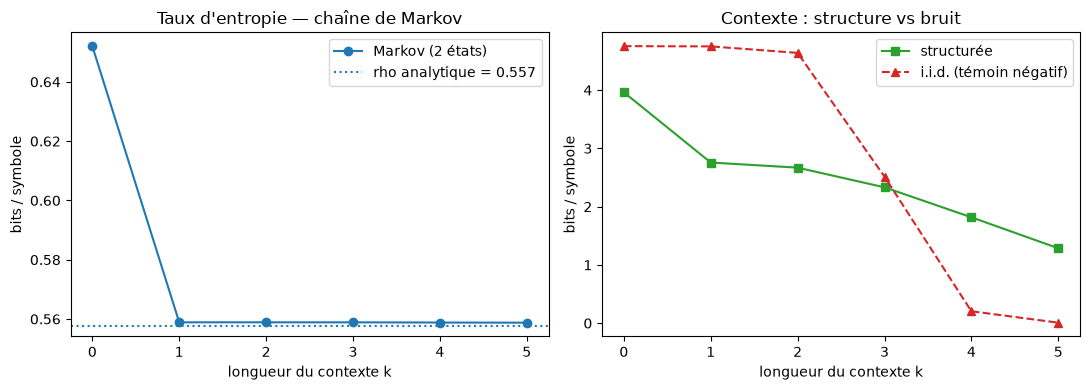

In [3]:
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt

# --- Source structurée : loi de lettres Zipf + mémoire de répétition ---
def source_structuree(n, seed=7):
    g = np.random.default_rng(seed)
    w = 1.0 / np.arange(1, A + 1)          # Zipf sur les 27 symboles
    w = w / w.sum()
    s = np.zeros(n, dtype=np.int64)
    s[0] = int(g.choice(A, p=w))
    for t in range(1, n):
        s[t] = s[t-1] if g.random() < 0.5 else int(g.choice(A, p=w))
    return s

# --- Source i.i.d. : tirage uniforme sans mémoire (témoin négatif) ---
def source_iid(n, seed=11):
    g = np.random.default_rng(seed)
    return g.integers(0, A, size=n).astype(np.int64)

m = 120_000
txt = source_structuree(m)
iid = source_iid(m)

ordres = list(range(0, 6))
def courbe(src):
    return [h0(src) if k == 0 else h_conditionnelle(src, k) for k in ordres]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(ordres, courbe(s), "o-", color="tab:blue", label="Markov (2 états)")
ax1.axhline(rho_analytique, color="tab:blue", ls=":",
            label=f"rho analytique = {rho_analytique:.3f}")
ax1.set_title("Taux d'entropie — chaîne de Markov")
ax1.set_xlabel("longueur du contexte k")
ax1.set_ylabel("bits / symbole")
ax1.set_xticks(ordres)
ax1.legend()

ax2.plot(ordres, courbe(txt), "s-", color="tab:green", label="structurée")
ax2.plot(ordres, courbe(iid), "^--", color="tab:red",  label="i.i.d. (témoin négatif)")
ax2.set_title("Contexte : structure vs bruit")
ax2.set_xlabel("longueur du contexte k")
ax2.set_ylabel("bits / symbole")
ax2.set_xticks(ordres)
ax2.legend()

fig.tight_layout()
plt.show()

In [4]:
def bilan(src, nom):
    """Tableau de synthèse par source : H0, H(·|1), H(·|2),
    information mutuelle d'ordre 1 et abaissement 0->1, pour `src` nommée `nom`."""
    h0v, h1v, h2v = h0(src), h_conditionnelle(src, 1), h_conditionnelle(src, 2)
    im = info_mutuelle_ordre1(src)
    print(f"{nom :>18} :  H0={h0v:6.3f}   H(·|1)={h1v:6.3f}   H(·|2)={h2v:6.3f}"
          f"   I(·;·)={im:5.3f}   abaissement 0->1={h0v-h1v:6.3f}")

print("Borne par symbole (bits) selon la présence ou non de structure :\n")
bilan(txt, "source structurée")
bilan(iid, "source i.i.d.")
print(f"\nRappel : log2(27) = {np.log2(A):.3f} bits — le plafond d'une source uniforme sans mémoire.")

Borne par symbole (bits) selon la présence ou non de structure :

 source structurée :  H0= 3.963   H(·|1)= 2.757   H(·|2)= 2.669   I(·;·)=1.206   abaissement 0->1= 1.206
     source i.i.d. :  H0= 4.755   H(·|1)= 4.751   H(·|2)= 4.639   I(·;·)=0.004   abaissement 0->1= 0.004

Rappel : log2(27) = 4.755 bits — le plafond d'une source uniforme sans mémoire.


### Lecture du contraste

Sur la source **structurée**, la connaissance du symbole précédent fait tomber la borne de ~4,0 à ~2,8 bits/symbole : le voisin porte près d'un tiers de l'incertitude. Sur la source **i.i.d.**, rien ne bouge **de l'ordre 0 à l'ordre 1** — H0 ≈ H(·|1) ≈ log2(27) : sans structure, aucun contexte ne descend la borne, et la mesure ne **fabrique** pas de structure fictive. Le repli à l'ordre 2 (0,116 bit) est le biais d'estimation vu au §5, pas de la structure. Ce témoin négatif est ce qui rend l'abaissement observé sur la source structurée **attribuable à la mémoire** et non à un biais d'estimation. C'est le même geste qu'au carnet 04, où les octets aléatoires servaient de contrôle au banc de codecs.

## 6. Où cela se retrouve dans la série

Cette géométrie — *borne par symbole* en haut, *borne réelle* en bas, le codec entre les deux — éclaire en retour les carnets précédents :

- **03 (LZ77)** remplace une répétition par une référence dans une fenêtre : la fenêtre est un **contexte**, et la copie est exactement la prédiction « ce symbole était prévisible sachant le contexte ». Le carnet 03 observait qu'un codec descend sous l'entropie des octets : le présent carnet donne la mesure de la borne qu'il approche.
- **04 (ANS)** code chaque symbole en lui donnant exactement `−log2 p(s)` bits, où `p` est la probabilité **modélisée**. Quand le modèle est conditionnel (porté par l'état du codeur), c'est `H(X | contexte)` que ANS sature, pas `H(X)` — c'est le mécanisme précis par lequel la sortie de ~0,09 bit/symbole du carnet 04 est possible.
- **01/01b (Huffman, Kraft)** restent exacts dans leur cadre : pour une source **sans mémoire**, la borne est `H(X)` et Huffman la sature. Ce carnet ne les contredit pas, il explicite leur hypothèse.

Le lecteur qui veut pousser vers la théorie de l'estimation trouvera dans le carnet 06 le prolongement algorithmique : la complexité de Kolmogorov est la borne ultime, **non calculable** — le taux d'entropie en est la version calculable, pour les sources stationnaires.

## 7. Exercices

Les trois exercices prolongent la démarche du carnet : mesurer, contrôler, confronter à une valeur connue. Chaque cellule attend une implémentation (`return None` par défaut) ; le carnet s'exécute de bout en bout même non complétés.

In [5]:
# Exercice 1 — entropie conditionnelle par empilement
# On a mesuré H(X_t | X_{t-1}) avec la table jointe complète. Écrire une fonction
# qui calcule la même chose en itérant sur les contextes observés : pour chaque
# contexte c rencontré au moins deux fois, entropie locale du symbole suivant,
# pondérée par la fréquence du contexte. Vérifier l'égalité des deux méthodes
# sur la source structurée (écart < 1e-9).
def h_conditionnelle_par_contexte(s):
    # TODO etudiant : construire les contextes, grouper par contexte,
    # moyenne pondérée des entropies locales
    return None

print("Exercice 1 a completer : h_conditionnelle_par_contexte(s)")

Exercice 1 a completer : h_conditionnelle_par_contexte(s)


In [6]:
# Exercice 2 — le plateau de la courbe
# La courbe H(X_t | contexte de longueur k) est décroissante puis plate.
# Écrire une fonction qui, pour une source donnée, renvoie l'ordre k* au-delà
# duquel le gain marginal H(·|k-1) - H(·|k) passe sous un seuil (par défaut
# 0.01 bit). Tester sur : la chaîne de Markov (attendu k* = 1), la source
# structurée (quel est son ordre mémoire réel ?), la source i.i.d. (attendu k* = 0).
def ordre_memoire(src, seuil=0.01, k_max=6):
    # TODO etudiant : balayer k, comparer le gain marginal au seuil
    return None

print("Exercice 2 a completer : ordre_memoire(src)")

Exercice 2 a completer : ordre_memoire(src)


In [7]:
# Exercice 3 — le contrôle négatif et le biais d'échantillonnage
# La source i.i.d. uniforme ne doit montrer AUCUNE réduction en fonction de
# l'ordre k : c'est ce qui prouve que la méthode n'invente pas de structure.
# a) Vérifier sur le panel 2 que la courbe i.i.d. est plate autour de log2(27).
# b) Compter, pour la source i.i.d., combien de contextes d'ordre 1 (27 possibles)
#    et d'ordre 3 (27^3 possibles) sont effectivement observés dans l'échantillon.
#    Expliquer pourquoi un alphabet trop grand (256 octets) avec un échantillon
#    fin fait s'effondser faussement l'estimation vers 0.
def contextes_observes(s, order):
    # TODO etudiant : compter les contextes distincts réellement vus
    return None

print("Exercice 3 a completer : contextes_observes(s, order)")

Exercice 3 a completer : contextes_observes(s, order)


## Conclusion

Le carnet a donné un corps au principe annoncé par la série : **le contexte rétrécit la borne**. L'entropie par symbole H(X) du carnet 01 est la borne d'une source **sans mémoire** ; une source à mémoire est bornée par son **taux d'entropie** ρ = limₖ H(X_t | X_{t-1}…X_{t-k}), toujours plus bas. Le témoin rigoureux l'établit sans approximation cachée : une chaîne de Markov dont le taux analytique est connu à l'avance, que l'estimation empirique retrouve à ~10⁻³ près (écart mesuré 0,0014), avec une courbe qui s'aplatit exactement à l'ordre mémoire réel. Le contrôle négatif (source i.i.d. plate) montre que la méthode n'invente pas de structure — et l'exercice 3 explique le piège d'échantillonnage qui la ferait mentir sur un alphabet trop grand.

C'est ce ρ, et non H(X), que LZ77 (03) et ANS (04) approchent en pratique : LZ77 avec ses contextes de longue portée, ANS en codant chaque symbole sur le nombre d'octets que la distribution conditionnelle lui alloue. Les carnets 01 et 01b restaient exacts — mais dans leur cadre sans mémoire, dont la borne était bien l'entropie par symbole.

**Navigation** : [Index de la série](README.md) | [Compression-08 — Assemblage vectoriel d'un document](Compression-08-Assemblage-Vectoriel-Python.ipynb)